In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from statsmodels.api import OLS
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from ISLP.models import ModelSpec as MS
from functools import partial

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from ISLP.models import \
(Stepwise,
sklearn_selected,
sklearn_selection_path)
!pip install l0bnb
from l0bnb import fit_path

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for l0bnb: filename=l0bnb-1.0.0-py3-none-any.whl size=22405 sha256=13fb41f4dd99abf9fb67fc4dc3f34e30816320d197e1b4b5a4fed6f567d6cc4f
  Stored in directory: c:\users\fatima zahra\appdata\local\pip\cache\wheels\ec\e0\1d\fc5db86912830a11a00b6bcb57c7bb84456e3b97cea4b4d570
Successfully built l0bnb


Exercises:

Conceptual:

(a)

Smallest Training RSS for size k: Best Subset Selection will always have the smallest (or equal) training RSS compared to Forward and Backward Stepwise selection

Forward vs. Backward Stepwise might find the absolute optimal subset for a given $k$, or they might get trapped in a local optimum due to their greedy search rules. Thus, Best Subset guarantees an RSS that is less than or equal to the RSS of the stepwise methods for any given $k$.

(b)

We cannot tell which method will have the smallest test RSS. Best Subset might overfit the training data and perform worse on test data, or it might identify the true underlying model and perform better. The outcome depends entirely on the true data-generating process and the noise level in the dataset.

(c)

i:   True
ii:  True 
iii: False 
iv:  False
v:   False 

Exercise 2:

**(a) The Lasso relative to Least Squares: (iii)**

By introducing a small increase in bias, Lasso significantly reduces variance. Prediction accuracy improves when the increase in bias is smaller than the decrease in variance.


**(b) Ridge Regression relative to Least Squares: (iii)**

Bias-Variance Trade-off: Like Lasso, Ridge trades a minor increase in bias for a substantial reduction in variance. Prediction accuracy improves when the increase in bias is less than the decrease in variance.


**(c) Non-Linear Methods relative to Least Squares: (ii)**

Bias-Variance Trade-off:** Greater flexibility drastically reduces bias but increases model variance. Prediction accuracy improves when the increase in variance is less than the reduction in bias.



Exercise 3:

**(a) Training RSS: iv. Steadily decrease**

**Reasoning:** Expanding $s$ relaxes restrictions on parameters, allowing the model to fit the training data more closely and reducing training error monotonically.



**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape**

**Reasoning:** Starting at $s = 0$ (high bias, zero variance), increasing $s$ reduces significant bias, lowering test error. Past an optimal point, high variance takes over as the model overfits, causing test RSS to rise again in a U-shape.



**(c) Variance: iii. Steadily increase**

**Reasoning:** Higher flexibility allows the model to become more sensitive to random noise and fluctuations in the training set.


**(d) (Squared) Bias: iv. Steadily decrease**

**Reasoning:** Allowing coefficients greater freedom lets the model capture true underlying relationships better, reducing systematic error (bias).


**(e) Irreducible Error: v. Remain constant**

**Reasoning:** Irreducible error is intrinsic noise in the data generation process and cannot be affected by parameter tuning or model choice.


Exercise 4:

**(a) Training RSS: iii. Steadily increase**

**Reasoning:** At $\lambda = 0$, the Ordinary Least Squares (OLS) fit directly minimizes training RSS. As $\lambda$ increases, the penalty forces coefficients away from their OLS values toward zero, restricting flexibility and continuously increasing training RSS.



**(b) Test RSS: ii. Decrease initially, and then eventually start increasing in a U shape**

**Reasoning:** At $\lambda = 0$, OLS can overfit due to high variance. Increasing $\lambda$ initially reduces variance significantly with only a slight increase in bias, dropping test RSS. Past the optimal $\lambda$, heavy shrinkage causes high bias, raising test RSS again in a U-shape.



**(c) Variance: iv. Steadily decrease**

**Reasoning:** Restricting parameter freedom reduces the model's sensitivity to random sample fluctuations. As $\lambda \to \infty$, all $\beta_j \to 0$, and variance approaches zero.



**(d) (Squared) Bias: iii. Steadily increase**

**Reasoning:** Forcing coefficients toward zero reduces the model's capacity to represent the true underlying relationship in the data, steadily increasing systematic bias.



**(e) Irreducible Error: v. Remain constant**

**Reasoning:** Irreducible error represents intrinsic noise in the data-generating process and is unaffected by tuning parameters or model fitting.


Exercise 5

(a)

n = 2, p = 2, $\hat{\beta}_0 = 0$

Identical predictor values: $x_{11} = x_{12} = x_1$ and $x_{21} = x_{22} = x_2$

Zero-centered conditions: $y_1 + y_2 = 0$, and $x_{11} + x_{21} = 0$


The model prediction for observation $i$ is:


$\hat{y}_i = \beta_1 x_{i1} + \beta_2 x_{i2} = (\beta_1 + \beta_2) x_{i1}$

$\text{RSS} = (y_1 - (\beta_1 + \beta_2)x_1)^2 + (y_2 - (\beta_1 + \beta_2)x_2)^2$

$\text{RSS} = (y_1 - (\beta_1 + \beta_2)x_1)^2 + (-y_1 + (\beta_1 + \beta_2)x_1)^2 = 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2$

Substituting RSS into the Ridge Regression optimization equation yields:

$$\min_{\beta_1, \beta_2} \left\{ 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\beta_1^2 + \beta_2^2) \right\}$$

(b)

From (a), the Ridge objective function to minimize is:


$f(\beta_1, \beta_2) = 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\beta_1^2 + \beta_2^2)$

Taking partial derivatives with respect to $\beta_1$ and $\beta_2$, and setting them to $0$:

*Derivative with respect to $\beta_1$:*

$\frac{\partial f}{\partial \beta_1} = -4x_1\left(y_1 - (\beta_1 + \beta_2)x_1\right) + 2\lambda\beta_1 = 0$

$2\lambda\hat{\beta}_1 = 4x_1\left(y_1 - (\hat{\beta}_1 + \hat{\beta}_2)x_1\right)$


*Derivative with respect to $\beta_2$:*

$\frac{\partial f}{\partial \beta_2} = -4x_1\left(y_1 - (\beta_1 + \beta_2)x_1\right) + 2\lambda\beta_2 = 0$

$2\lambda\hat{\beta}_2 = 4x_1\left(y_1 - (\hat{\beta}_1 + \hat{\beta}_2)x_1\right)$

$2\lambda\hat{\beta}_1 = 2\lambda\hat{\beta}_2$

Dividing by $2\lambda$ (since $\lambda > 0$):


$\hat{\beta}_1 = \hat{\beta}_2$


(c)


From Part (a), the Residual Sum of Squares RSS for n=2 zero-centered observations with identical predictors simplifies to:


RSS = $$2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2$$


Substituting this RSS and the $L_1$ regularization penalty $\lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{})$ into the Lasso objective function yields:

$$\min_{\beta_1, \beta_2} \left\{ 2\left(y_1 - (\beta_1 + \beta_2)x_1\right)^2 + \lambda (\vert{}\beta_1\vert{} + \vert{}\beta_2\vert{}) \right\}$$


(d)

**Proof of Non-Uniqueness:**

*RSS Dependence:* 
The Residual Sum of Squares depends strictly on the sum of the coefficients, $S = \beta_1 + \beta_2$. Let $S^*$ be the optimal combined value that minimizes the overall objective function. Any pair $(\hat{\beta}_1, \hat{\beta}_2)$ satisfying $\hat{\beta}_1 + \hat{\beta}_2 = S^*$ yields the exact same minimal RSS.


$\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{} = \hat{\beta}_1 + \hat{\beta}_2 = S^*$



Because this sum is fixed at $S^*$, the penalty

$\lambda(\vert{}\hat{\beta}_1\vert{} + \vert{}\hat{\beta}_2\vert{}) = \lambda S^*$

remains constant regardless of how $S^*$ is split between $\hat{\beta}_1$ and $\hat{\beta}_2$.


Exercise 6:

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_15340\391686562.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


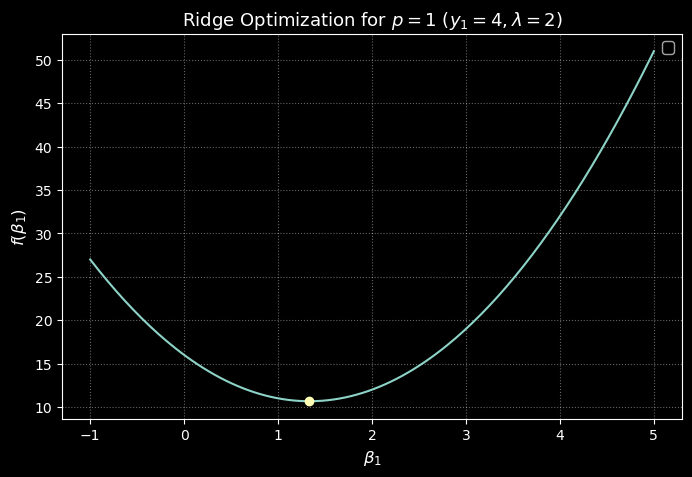

In [21]:
#(a)

import matplotlib.pyplot as plt
import numpy as np

y1 = 4
lambda_param = 2
beta1_opt = y1 / (1 + lambda_param)  
f_opt = (y1 - beta1_opt) ** 2 + lambda_param * (beta1_opt**2)  
beta1 = np.linspace(-1, 5, 200)
f_vals = (y1 - beta1) ** 2 + lambda_param * (beta1**2)

plt.figure(figsize=(8, 5))
plt.plot(
    beta1,
    f_vals
)
plt.plot(
    beta1_opt,
    f_opt,
    marker="o"
)

plt.title(
    r"Ridge Optimization for $p=1$ ($y_1=4, \lambda=2$)",
    fontsize=13,
)
plt.xlabel(r"$\beta_1$", fontsize=12)
plt.ylabel(r"$f(\beta_1)$", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.4)

plt.show()

C:\Users\Fatima zahra\AppData\Local\Temp\ipykernel_15340\3085724618.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


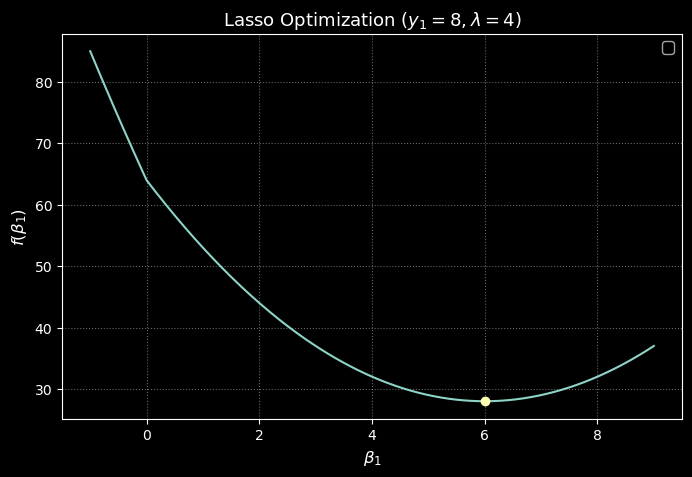

In [23]:

y1 = 8
lambda_param = 4
beta1_opt = y1 - lambda_param / 2 
f_opt = (y1 - beta1_opt) ** 2 + lambda_param * np.abs(beta1_opt)  
beta1 = np.linspace(-1, 9, 300)
f_vals = (y1 - beta1) ** 2 + lambda_param * np.abs(beta1)

# Plot
plt.style.use("dark_background")
plt.figure(figsize=(8, 5))
plt.plot(
    beta1,
    f_vals
)
plt.plot(
    beta1_opt,
    f_opt,
    marker="o",
)

plt.title(r"Lasso Optimization ($y_1 = 8, \lambda = 4$)", fontsize=13)
plt.xlabel(r"$\beta_1$", fontsize=12)
plt.ylabel(r"$f(\beta_1)$", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.4)

plt.show()

Exercise 7

(a)

The model says $y_i = \beta_0 + \sum_{j=1}^p x_{ij}\beta_j + \epsilon_i$, where the errors $\epsilon_i$ follow a Normal distribution $N(0, \sigma^2)$.

This means each data point $y_i$ is normally distributed around its prediction $\hat{y}_i$:


$p(y_i \mid X, \beta, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{\left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2}{2\sigma^2} \right)$


Since errors $\epsilon_1, \dots, \epsilon_n$ are independent, the total likelihood $L(\beta)$ for all $n$ observations is the product ($\prod$) of individual probabilities:

$L(\beta) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{\left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2}{2\sigma^2} \right)$

Pulling the product inside the exponential turns the individual squared terms into a sum (which is RSS!):

$L(\beta) = \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right)$


$\text{Likelihood: } L(\beta) = \left(2\pi\sigma^2\right)^{-n/2} \exp\left( -\frac{1}{2\sigma^2} \text{RSS} \right)$

where $\text{RSS} = \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2$.


(b)


We are given that each coefficient $\beta_j$ (for $j = 1, \dots, p$) follows a double-exponential (Laplace) distribution:


$p(\beta_j) = \frac{1}{2b} \exp\left( -\frac{\vert{}\beta_j\vert{}}{b} \right)$

Since all $p$ coefficients are independent, the total prior probability $p(\beta)$ for the entire vector $\beta = (\beta_1, \dots, \beta_p)$ is the product of their individual probabilities:

$p(\beta) = p(\beta_1) \times p(\beta_2) \times \dots \times p(\beta_p)$

$p(\beta) = \prod_{j=1}^p \frac{1}{2b} \exp\left( -\frac{\vert{}\beta_j\vert{}}{b} \right)$

Multiplying $\frac{1}{2b}$ by itself $p$ times gives $\left(\frac{1}{2b}\right)^p$.

When multiplying exponentials, we add their exponents together:

$p(\beta) = \left(\frac{1}{2b}\right)^p \exp\left( -\frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$


From Part (a), the data likelihood is:


$p(Y \mid X, \beta) = \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right)$



Bayes' Theorem states that the Posterior probability is proportional to the Likelihood times the Prior:

$\text{Posterior} \propto \text{Likelihood} \times \text{Prior}$

$p(\beta \mid Y, X) \propto p(Y \mid X, \beta) \times p(\beta)$

Now substitute the full expressions:

$p(\beta \mid Y, X) \propto \left[ \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 \right) \right] \times \left[ \left(\frac{1}{2b}\right)^p \exp\left( -\frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right) \right]$

The constant terms outside the exponentials, $\left(\frac{1}{2\pi\sigma^2}\right)^{n/2}$ and $\left(\frac{1}{2b}\right)^p$, do not depend on $\beta$. Since we are using proportionality ($\propto$), we can absorb them into the constant.


Combining the two exponential terms using the rule $\exp(A) \times \exp(B) = \exp(A + B)$:



$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$



Combining the Likelihood from Part (a) and the Prior via Bayes' theorem:


$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right)$

where $\text{RSS} = \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2$.

(c)

$\hat{\beta}_{\text{mode}} = \arg\max_{\beta} p(\beta \mid Y, X) = \arg\max_{\beta} \log p(\beta \mid Y, X)$


$\log p(\beta \mid Y, X) \propto -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{}$

$\arg\min_{\beta} \left\{ \frac{1}{2\sigma^2} \text{RSS} + \frac{1}{b} \sum_{j=1}^p \vert{}\beta_j\vert{} \right\}$

$\arg\min_{\beta} \left\{ \text{RSS} + \lambda \sum_{j=1}^p \vert{}\beta_j\vert{} \right\} \quad \text{where } \lambda = \frac{2\sigma^2}{b}$



This matches the Lasso objective function exactly, proving that the Lasso estimate is the posterior mode.



(d)

Each coefficient $\beta_j \sim N(0, c)$ has probability density:

$p(\beta_j) = \frac{1}{\sqrt{2\pi c}} \exp\left( -\frac{\beta_j^2}{2c} \right)$

$p(\beta) = \prod_{j=1}^p \frac{1}{\sqrt{2\pi c}} \exp\left( -\frac{\beta_j^2}{2c} \right) = \left(\frac{1}{2\pi c}\right)^{p/2} \exp\left( -\frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right)$

Form the Posterior via Bayes' Theorem:

$p(\beta \mid Y, X) \propto p(Y \mid X, \beta) \times p(\beta)$



Substitute the Likelihood from Part (a) and this Normal Prior:

$p(\beta \mid Y, X) \propto \left[ \left(\frac{1}{2\pi\sigma^2}\right)^{n/2} \exp\left( -\frac{1}{2\sigma^2} \text{RSS} \right) \right] \times \left[ \left(\frac{1}{2\pi c}\right)^{p/2} \exp\left( -\frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right) \right]$

Combining exponents gives:

$p(\beta \mid Y, X) \propto \exp\left( -\frac{1}{2\sigma^2} \sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\right)^2 - \frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right)$



(e)

Take the log of the posterior from Part (d):

$\log p(\beta \mid Y, X) \propto -\frac{1}{2\sigma^2} \text{RSS} - \frac{1}{2c} \sum_{j=1}^p \beta_j^2$


Maximizing this is equivalent to minimizing the negative:

$\arg\min_{\beta} \left\{ \frac{1}{2\sigma^2} \text{RSS} + \frac{1}{2c} \sum_{j=1}^p \beta_j^2 \right\}$


Multiply by $2\sigma^2$:

$\arg\min_{\beta} \left\{ \text{RSS} + \frac{\sigma^2}{c} \sum_{j=1}^p \beta_j^2 \right\}$


Setting $\lambda = \frac{\sigma^2}{c}$, this becomes:

$$\arg\min_{\beta} \left\{ \text{RSS} + \lambda \sum_{j=1}^p \beta_j^2 \right\}$$


This is precisely the Ridge Regression objective function. Thus, the Ridge estimate is the mode of this posterior.

**Why is it also the Mean?**
- The Likelihood is Gaussian (Normal).
- The Prior is Gaussian (Normal).
- The product of two Gaussian distributions (conjugate prior setup) results in a posterior distribution that is **also Gaussian (Multivariate Normal)**.
- A Normal distribution is perfectly **symmetric** and bell-shaped. For any symmetric distribution, the peak (**mode**) is located at the center of mass (**mean**).
- Therefore, for this Gaussian posterior, $\text{mode} = \text{mean}$.